# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 32: Estudo da Classe SMALL

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

A classe SMALL (navios com menos de 50 m) tem o pior recall em quase todos os modelos. Os Notebooks 30 e 31 mostraram que as quatro entradas erram, em boa parte, as mesmas gravações. Aqui estudamos o SMALL diretamente com 16 modelos (RF, SVM, MLP e BiGRU × MEL, LOFAR, HHT e DEMON):

1. Quantos dos 16 modelos erram cada gravação SMALL?
2. Quais gravações quase todos erram (o **núcleo**)? São gravações isoladas ou navios inteiros?
3. Ter o mesmo navio no treino muda o erro?
4. O núcleo difere em metadados ou em medidas acústicas simples?
5. Para que classe vão os erros?

**Resumo:**
- Das 476 gravações SMALL de teste, só **26 (5,5%) formam o núcleo** (≥ 15 dos 16 modelos erram), de **15 navios**. Outras 35 (7,4%) são fáceis (≤ 4 erram); **415 (87,2%) ficam no meio**: o acerto depende do modelo e da entrada.
- Recall SMALL dos 16 modelos: de 12,0% a 57,6%.
- No núcleo, 71% das predições vão para **LARGE**.
- No split oficial, ter o navio no treino reduz o erro no SMALL em média 8,8 pontos (de -17,4 a 0,7 entre os 16 modelos).
- **Medidas acústicas:** Com p < 0,05 entre fácil, meio e núcleo: **centroide (Hz)** (p < 0,001, ρ = -0,38), **planura 0–5 kHz** (p < 0,001, ρ = -0,50), **energia 0-200 Hz (%)** (p < 0,001, ρ = 0,48), **energia 200-1000 Hz (%)** (p = 0,022, ρ = -0,32), **energia 1000-5000 Hz (%)** (p < 0,001, ρ = -0,52), **energia 5000-24000 Hz (%)** (p < 0,001, ρ = -0,29). Ganho mediano no CPA: fácil 4,3 dB, meio 3,2 dB, núcleo 3,5 dB (classes: SMALL 3,3 dB, MEDIUM 4,0 dB, LARGE 6,0 dB, BACKGROUND -0,0 dB). Distância mediana do pico de nível ao CPA anotado: fácil 32 s, meio 33 s, núcleo 42 s.

Predição por gravação = voto majoritário das janelas; "erram" = média sobre os 5 folds em que a gravação é teste. Todas as tabelas são calculadas na execução (`notebooks/src/iara_results.py`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu, chi2_contingency, spearmanr
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 2); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
CLS = dict(enumerate(R.CLASSES))
SMALL = 0

# 16 modelos: 4 famílias × 4 entradas (os mesmos dos Notebooks 30 e 31)
FAM = {
    'RF': {'MEL': 'rf_mel5s_n100_balanced_4c', 'LOFAR': 'rf_lofar5s_n100_balanced_4c',
           'HHT': 'rf_hht_n100_balanced_4c', 'DEMON': 'rf_demon_n100_balanced_4c'},
    'SVM': {'MEL': 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0',
            'LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15',
            'HHT': 'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c',
            'DEMON': 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_4c'},
    'MLP': {'MEL': 'mlp', 'LOFAR': 'mlp_lofar', 'HHT': 'mlp_hht_h32-16_e30_4c', 'DEMON': 'mlp_demon_h32-16_e30_4c'},
    'BiGRU': {'MEL': 'bigru_att_mel5s_h64_s15-5_e20_4c', 'LOFAR': 'bigru_att_lofar5s_h128_s15-5_e15_4c',
              'HHT': 'bigru_att_hht_h64_s15-5_e20_4c', 'DEMON': 'bigru_att_demon_h64_s15-5_e20_4c'},
}
MOD = {f'{f} {r}': e for f, reps in FAM.items() for r, e in reps.items()}
NM = len(MOD)

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip()
for c in ('Length', 'CPA time', 'Recording time', 'Rain', 'Wind', 'Sea state'):
    meta[c] = pd.to_numeric(meta[c], errors='coerce')
meta['Arquivo'] = meta.Dataset + '-' + meta.ID + '.wav'
meta = meta.set_index(meta.ID.astype(int))

# Predições alinhadas por fold (só gravações presentes nos 16 modelos) + navio no treino do fold
AL = R.aligned(list(MOD.values()))
rows = []
for k, d in AL.items():
    sp = pd.read_csv(os.path.join(R.exp_dir(FAM['RF']['LOFAR']), 'eval', f'fold_{k}', f"{FAM['RF']['LOFAR']}_split.csv"))
    trn_ships = set(meta.loc[sp[sp.Subset == 'trn'].File.astype(int), 'Ship ID'])
    P = np.column_stack([d[e].values for e in MOD.values()])
    E = P != d.Target.values[:, None]
    x = pd.DataFrame(E.astype(int), columns=list(MOD))
    x['fold'], x['File'], x['Target'], x['n_err'] = k, d.File.values, d.Target.values, E.sum(1)
    for c in range(4):
        x[f'pred {CLS[c]}'] = (P == c).sum(1)
    x['navio no treino'] = [s in trn_ships for s in meta.loc[d.File, 'Ship ID']]
    rows.append(x)
I = pd.concat(rows, ignore_index=True)

# Uma linha por gravação: média sobre os folds em que ela foi teste (5, uma vez por repetição)
G = I.groupby('File').agg(Target=('Target', 'first'), n_err=('n_err', 'mean'), vezes=('fold', 'size'),
                          **{f'pred {CLS[c]}': (f'pred {CLS[c]}', 'mean') for c in range(4)},
                          **{m: (m, 'mean') for m in MOD})
G['Classe'] = G.Target.map(CLS)
G['grupo'] = np.select([G.n_err >= 15, G.n_err <= 4], ['núcleo', 'fácil'], 'meio')
G = G.join(meta[['Arquivo', 'Dataset', 'Ship ID', 'Name', 'DETAILED TYPE', 'Length', 'CPA time', 'Recording time',
                 'Rain', 'Wind', 'Sea state']], on='File')

FEAT_CSV = os.path.join(R.ROOT, 'reports', 'small', 'features_acusticas.csv')
FEAT = pd.read_csv(FEAT_CSV).set_index('File') if os.path.exists(FEAT_CSV) else None
if FEAT is not None:
    G = G.join(FEAT, on='File')
S = G[G.Target == SMALL].copy()
print(f'{len(G)} gravações de teste; {len(S)} SMALL; medidas acústicas: {FEAT is not None}')

1706 gravações de teste; 476 SMALL; medidas acústicas: True


## 1. Quantos modelos erram cada gravação?

Para cada gravação de teste contamos quantos dos 16 modelos erram (média dos 5 folds em que ela é teste). Grupos: **fácil** (≤ 4 erram), **meio** (5 a 14), **núcleo** (≥ 15).

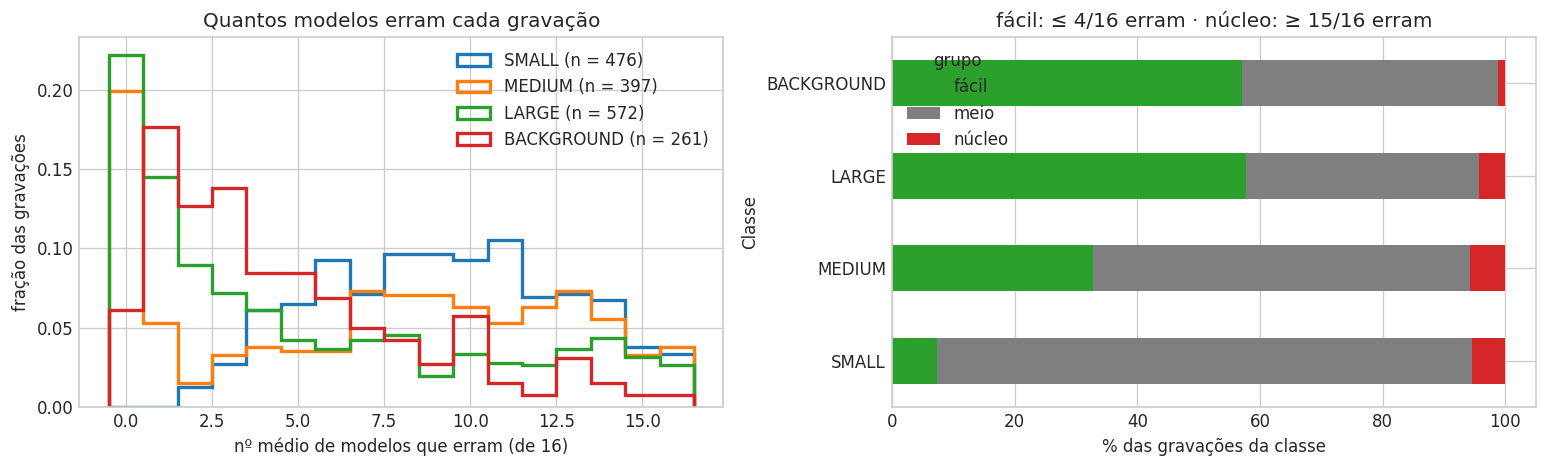

grupo,fácil,meio,núcleo,total
Classe,,,,
SMALL,35,415,26,476
MEDIUM,130,244,23,397
LARGE,330,217,25,572
BACKGROUND,149,109,3,261


Recall SMALL (%) por modelo:


,MEL,LOFAR,HHT,DEMON,oráculo das 4 entradas
RF,57.6,47.7,52.7,52.8,86.0
SVM,50.7,38.0,43.3,12.0,76.4
MLP,44.8,46.5,28.6,32.0,76.2
BiGRU,45.1,55.9,33.5,40.4,82.3


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(-0.5, NM + 1.5, 1)
for c in range(4):
    g = G[G.Target == c]
    ax[0].hist(g.n_err, bins=bins, histtype='step', lw=2, density=True, label=f'{CLS[c]} (n = {len(g)})')
ax[0].set_xlabel(f'nº médio de modelos que erram (de {NM})'); ax[0].set_ylabel('fração das gravações'); ax[0].legend()
ax[0].set_title('Quantos modelos erram cada gravação')
gr = G.groupby(['Classe', 'grupo']).size().unstack().reindex(R.CLASSES)[['fácil', 'meio', 'núcleo']]
(gr.div(gr.sum(1), axis=0) * 100).plot.barh(stacked=True, ax=ax[1], color=['tab:green', 'tab:gray', 'tab:red'])
ax[1].set_xlabel('% das gravações da classe'); ax[1].set_title(f'fácil: ≤ 4/{NM} erram · núcleo: ≥ 15/{NM} erram')
plt.tight_layout(); plt.show()
GR = gr.assign(total=gr.sum(1))
display(GR)

# Recall SMALL por modelo (por gravação, média dos folds)
REC = pd.DataFrame({f: {r: 100 * (1 - S[f'{f} {r}'].mean()) for r in FAM[f]} for f in FAM}).T
REC['oráculo das 4 entradas'] = [100 * np.mean([1 - (d[list(FAM[f].values())].values != 0).all(1).mean()
                                               for d in [x[x.Target == SMALL] for x in AL.values()]]) for f in FAM]
print('Recall SMALL (%) por modelo:'); display(REC.round(1))

**Leitura.**
- SMALL: 35 fáceis, 415 no meio, 26 no núcleo. Nas outras classes, o núcleo é de MEDIUM 23/397, LARGE 25/572, BACKGROUND 3/261.
- O que separa o SMALL das outras classes **não é o núcleo**, que é pequeno em todas, mas o **meio**: a maioria das gravações SMALL é acertada por alguns modelos e errada por outros.
- O oráculo das 4 entradas (algum modelo acerta) é otimista: escolhe o modelo certo depois de saber a resposta. Ele mostra que o acerto não é impossível, não que um combinador chegue lá.

## 2. O núcleo: gravações ou navios?

A lista é gravada em `reports/small/nucleo_small.csv`.

In [3]:
N = S[S.grupo == 'núcleo'].sort_values('n_err', ascending=False)
cols = ['Arquivo', 'Dataset', 'Ship ID', 'Name', 'DETAILED TYPE', 'Length', 'n_err', 'vezes',
        'pred SMALL', 'pred MEDIUM', 'pred LARGE', 'pred BACKGROUND']
LISTA = N[cols].rename(columns={'n_err': f'erram (de {NM})', 'Length': 'comprimento (m)', 'DETAILED TYPE': 'tipo',
                                'vezes': 'folds como teste'})
print(f'{len(N)} gravações SMALL no núcleo (≥ 15 dos {NM} modelos erram, média dos folds):')
display(LISTA.round(1))
LISTA.to_csv(os.path.join(R.ROOT, 'reports', 'small', 'nucleo_small.csv'))

# Gravação ou navio? Para cada navio com gravação no núcleo: as outras gravações dele também falham?
nav = S.groupby('Ship ID').agg(nome=('Name', 'first'), tipo=('DETAILED TYPE', 'first'), comprimento=('Length', 'first'),
                               gravações=('n_err', 'size'), no_núcleo=('grupo', lambda s: (s == 'núcleo').sum()),
                               erram_média=('n_err', 'mean'), erram_min=('n_err', 'min'), erram_max=('n_err', 'max'))
NAV = nav[nav.no_núcleo > 0].sort_values(['no_núcleo', 'erram_média'], ascending=False)
print('Navios com gravação no núcleo:')
display(NAV.round(1))

26 gravações SMALL no núcleo (≥ 15 dos 16 modelos erram, média dos folds):


,Arquivo,Dataset,Ship ID,Name,tipo,comprimento (m),erram (de 16),folds como teste,pred SMALL,pred MEDIUM,pred LARGE,pred BACKGROUND
File,,,,,,,,,,,,
450,A-0450.wav,A,456,PILOT 14,Pilot Vessel,12.0,16.0,3,0.0,0.0,15.7,0.3
501,B-0501.wav,B,454,PILOT 11,Pilot Vessel,13.0,16.0,4,0.0,0.0,16.0,0.0
923,C-0923.wav,C,450,PILOT 05,Pilot Vessel,11.0,16.0,4,0.0,0.2,15.8,0.0
590,B-0590.wav,B,456,PILOT 14,Pilot Vessel,12.0,16.0,2,0.0,14.0,2.0,0.0
1427,D-1427.wav,D,613,URANUS,Tug,25.0,16.0,4,0.0,0.0,6.0,10.0
1426,D-1426.wav,D,456,PILOT 14,Pilot Vessel,12.0,16.0,3,0.0,1.3,12.3,2.3
1226,D-1226.wav,D,458,PILOT BOAT I,Pilot Vessel,8.0,16.0,2,0.0,0.0,16.0,0.0
992,C-0992.wav,C,449,PILOT 02,Pilot Vessel,12.0,16.0,3,0.0,0.0,0.0,16.0
967,C-0967.wav,C,450,PILOT 05,Pilot Vessel,11.0,16.0,4,0.0,0.2,15.8,0.0


Navios com gravação no núcleo:


,nome,tipo,comprimento,gravações,no_núcleo,erram_média,erram_min,erram_max
Ship ID,,,,,,,,
456,PILOT 14,Pilot Vessel,12.0,87,6,9.0,2.3,16.0
450,PILOT 05,Pilot Vessel,11.0,4,3,14.0,8.0,16.0
454,PILOT 11,Pilot Vessel,13.0,41,2,10.3,2.0,16.0
458,PILOT BOAT I,Pilot Vessel,8.0,6,2,10.0,4.7,16.0
451,PILOT 08,Pilot Vessel,12.0,68,2,8.6,2.2,15.0
452,PILOT 09,Pilot Vessel,12.0,59,2,8.5,2.2,15.3
613,URANUS,Tug,25.0,1,1,16.0,16.0,16.0
448,PILOT 01,Pilot Vessel,11.0,1,1,15.2,15.2,15.2
503,SANDSHAVID,Fishing Vessel,48.0,1,1,15.2,15.2,15.2


**Leitura.**
- As 26 gravações do núcleo vêm de **15 navios**. 4 delas são de navios com uma só gravação SMALL de teste, então nesses casos não dá para separar "gravação ruim" de "navio difícil".
- Entre os 11 navios do núcleo com mais de uma gravação, nenhum tem **todas** as gravações no núcleo; em todos, outras gravações do mesmo navio são acertadas por parte dos modelos (ex.: PILOT 14 tem 87 gravações SMALL de teste e só 6 no núcleo). Quando o mesmo navio é acertado em uma gravação e errado em outra, o problema está mais na gravação que no navio.

## 3. Navio visto no treino

No 5×2cv oficial a separação é por gravação: o mesmo navio pode ter gravações no treino e no teste. Comparamos o erro das gravações SMALL de teste cujo navio **tem** gravação no treino do fold com as que **não têm**. Depois, o recall SMALL nos experimentos com split por navio do Notebook 29.

In [4]:
# Split oficial (por gravação): o navio da gravação de teste tem gravação no treino do mesmo fold?
Is = I[I.Target == SMALL]
VIS = pd.DataFrame({m: Is.groupby('navio no treino')[m].mean() * 100 for m in MOD}).T
VIS.columns = ['erro (%) navio NÃO visto', 'erro (%) navio visto']
VIS['Δ (visto − não visto)'] = VIS['erro (%) navio visto'] - VIS['erro (%) navio NÃO visto']
n_vis = Is.groupby('navio no treino').size()
print(f'Gravações SMALL de teste (somando os 10 folds): navio visto {n_vis.get(True, 0)}, não visto {n_vis.get(False, 0)}')
display(VIS.round(1))
NUC_VIS = 100 * Is.assign(nuc=Is.n_err >= 15).groupby('navio no treino').nuc.mean()
print('% das gravações SMALL de teste com ≥ 15 modelos errando:', NUC_VIS.round(1).to_dict())

# Split por navio (NB29): recall SMALL com controle por ID × por navio
SPL = []
for lab, tag in [('RF', 'rf'), ('SVM', 'svm2000'), ('MLP', 'mlp')]:
    for r in ('mel', 'lofar', 'hht'):
        try:
            a, b = R.fold_metrics(f'split_id_{tag}_{r}_4c'), R.fold_metrics(f'split_navio_{tag}_{r}_4c')
        except FileNotFoundError:
            continue
        SPL.append({'modelo': f'{lab} {r.upper()}', 'recall SMALL por ID': a.R_SMALL.mean(),
                    'recall SMALL por navio': b.R_SMALL.mean(), 'Δ': b.R_SMALL.mean() - a.R_SMALL.mean()})
SPL = pd.DataFrame(SPL).set_index('modelo')
display(SPL.round(1))

Gravações SMALL de teste (somando os 10 folds): navio visto 1535, não visto 245


,erro (%) navio NÃO visto,erro (%) navio visto,Δ (visto − não visto)
RF MEL,57.1,39.7,-17.4
RF LOFAR,58.8,51.1,-7.6
RF HHT,54.7,45.3,-9.4
RF DEMON,46.9,47.6,0.7
SVM MEL,62.4,47.2,-15.3
SVM LOFAR,66.9,61.0,-5.9
SVM HHT,61.2,55.7,-5.5
SVM DEMON,90.6,87.8,-2.9
MLP MEL,69.4,53.0,-16.4
MLP LOFAR,61.6,52.4,-9.3


% das gravações SMALL de teste com ≥ 15 modelos errando: {False: 12.2, True: 9.4}


,recall SMALL por ID,recall SMALL por navio,Δ
modelo,,,
RF MEL,60.0,47.2,-12.8
RF LOFAR,49.9,42.4,-7.5
RF HHT,53.5,43.0,-10.4
SVM MEL,53.6,47.0,-6.6
SVM LOFAR,41.1,39.2,-1.9
SVM HHT,25.6,32.9,7.3
MLP MEL,45.4,41.0,-4.4
MLP LOFAR,54.1,49.8,-4.3
MLP HHT,27.6,23.8,-3.8


**Leitura.**
- Só 13,8% das gravações SMALL de teste (245 de 1780, somando os 10 folds) são de navios **sem** gravação no treino: no protocolo oficial, quase todo teste SMALL é de um navio já visto.
- Erro no SMALL com o navio visto × não visto: Δ médio de -8,8 pontos (15 dos 16 modelos erram menos quando o navio foi visto).
- Fração de gravações com ≥ 15 modelos errando: 9,4% com o navio visto, 12,2% sem.
- **Split por navio (NB29):** recall SMALL cai em média 4,9 pontos (Δ entre -12,8 e +7,3 entre os 9 modelos). Parte do recall SMALL do protocolo oficial vem de reconhecer o mesmo navio.

## 4. Metadados: o que distingue o núcleo?

Comparação entre fácil, meio e núcleo (SMALL): comprimento, CPA, duração, vento, estado do mar, chuva (Kruskal-Wallis), subconjunto do IARA (χ²) e tipo de navio.

In [5]:
ORD = ['fácil', 'meio', 'núcleo']
num = ['Length', 'CPA time', 'Recording time', 'Wind', 'Sea state', 'Rain']
MT = S.groupby('grupo')[num].median().reindex(ORD)
LEN_MEAN = S.groupby('grupo').Length.mean().reindex(ORD)
MT.loc['p (Kruskal-Wallis)'] = [kruskal(*[S.loc[S.grupo == g, c].dropna() for g in ORD]).pvalue for c in num]
display(MT.round(3))

DS = pd.crosstab(S.grupo, S.Dataset).reindex(ORD)
p_ds = chi2_contingency(DS.values)[1]
print(f'Subconjunto × grupo (χ² {"p < 0,001" if p_ds < 0.001 else f"p = {p_ds:.3f}"}):'); display(DS)
DSp = S.groupby('Dataset').agg(gravações=('n_err', 'size'), erram_média=('n_err', 'mean'),
                               núcleo=('grupo', lambda s: (s == 'núcleo').sum()))
DSp['% no núcleo'] = 100 * DSp.núcleo / DSp.gravações
display(DSp.round(1))

TP = S.groupby('DETAILED TYPE').agg(gravações=('n_err', 'size'), navios=('Ship ID', 'nunique'),
                                    erram_média=('n_err', 'mean'), núcleo=('grupo', lambda s: (s == 'núcleo').sum()))
display(TP[TP.gravações >= 5].sort_values('gravações', ascending=False).round(1))

,Length,CPA time,Recording time,Wind,Sea state,Rain
grupo,,,,,,
fácil,12.00,150.0,300.00,4.60,3.00,0.00
meio,12.00,150.0,300.00,4.80,3.00,0.00
núcleo,12.00,150.0,300.00,4.85,3.00,0.00
p (Kruskal-Wallis),0.02,0.6,0.34,0.95,0.99,0.64


Subconjunto × grupo (χ² p = 0.157):


Dataset,A,B,C,D
grupo,,,,
fácil,7,6,8,14
meio,104,82,87,142
núcleo,2,2,9,13


,gravações,erram_média,núcleo,% no núcleo
Dataset,,,,
A,113,9.1,2,1.8
B,90,9.3,2,2.2
C,104,9.0,9,8.7
D,169,9.3,13,7.7


,gravações,navios,erram_média,núcleo
DETAILED TYPE,,,,
Pilot Vessel,321,15,9.1,20
Tug,87,34,9.5,1
Fishing Vessel,33,22,9.8,4
Offshore Supply Ship,8,3,8.9,0
High-Speed Craft,8,2,8.9,0
Pleasure Craft,7,4,9.9,1
Mooring Vessel,5,2,5.6,0


**Leitura.**
- Separam os grupos com p < 0,05: Length (p = 0,020); CPA, duração, vento, estado do mar e chuva não. Comprimento: mediana 12 m no núcleo e 12 m nas fáceis; média 15,0 / 17,4 / 14,7 m (fácil / meio / núcleo). O núcleo **não** está concentrado perto do limiar de 50 m.
- **Subconjunto:** p = 0,157 no χ²; o maior percentual de núcleo está em **C** (8,7%). Os subconjuntos do IARA diferem em local, período e equipamento de gravação, então essa diferença pode vir de qualquer um deles.
- **Tipo:** o SMALL é dominado por Pilot Vessel (321 gravações de apenas 15 navios, ~21 por navio). Muitas gravações do mesmo barco facilitam memorizar o navio em vez de aprender a classe.

## 5. Medidas acústicas simples

Sem calibração dos hidrofones, as medidas são relativas à própria gravação (`scratch/small_acoustic_features.py`):
- **ganho no CPA:** nível mediano em ±30 s do CPA anotado menos o nível mediano dos 30 s iniciais e finais. Aproxima o quanto o navio se destaca do fundo; perto de 0 dB, o navio mal aparece.
- **faixa dinâmica:** p95 − p5 do nível em janelas de 1 s.
- **|pico − CPA|:** distância entre o instante mais alto (média de 10 s) e o CPA anotado. Se o pico está longe do CPA, outra fonte (outro navio, ruído) pode dominar a gravação.
- **bandas, centroide e planura:** como a energia se distribui na frequência.

SMALL: medianas por grupo


,ganho no CPA (dB),faixa dinâmica (dB),|pico − CPA| (s),nível p50 (dBFS),centroide (Hz),planura 0–5 kHz,energia 0-200 Hz (%),energia 200-1000 Hz (%),energia 1000-5000 Hz (%),energia 5000-24000 Hz (%)
grupo,,,,,,,,,,
fácil,4.31,9.30e+00,32.00,-43.78,1784.16,0.46,31.68,17.95,24.61,9.39
meio,3.17,1.01e+01,33.00,-44.52,1324.75,0.22,54.69,16.51,13.08,8.25
núcleo,3.52,1.17e+01,42.50,-42.13,328.01,0.05,86.16,9.75,2.78,1.28
p (Kruskal-Wallis),0.34,3.29e-01,0.18,0.12,0.00,0.00,0.00,0.02,0.00,0.00
ρ Spearman com nº de erros,0.03,1.50e-01,0.04,0.09,-0.38,-0.50,0.48,-0.32,-0.52,-0.29
p (Spearman),0.57,1.00e-03,0.38,0.05,0.00,0.00,0.00,0.00,0.00,0.00


Todas as classes: medianas


,ganho no CPA (dB),faixa dinâmica (dB),|pico − CPA| (s),nível p50 (dBFS),centroide (Hz),planura 0–5 kHz,energia 0-200 Hz (%),energia 200-1000 Hz (%),energia 1000-5000 Hz (%),energia 5000-24000 Hz (%)
Classe,,,,,,,,,,
SMALL,3.32,10.16,33.0,-44.33,1311.93,0.22,54.95,16.41,12.66,7.90
MEDIUM,3.99,10.22,31.0,-42.50,1100.82,0.18,64.82,12.20,9.83,7.06
LARGE,6.02,12.56,28.0,-40.66,625.04,0.11,72.48,12.56,5.89,2.94
BACKGROUND,-0.00,2.73,41.0,-56.99,2046.29,0.25,34.20,24.56,11.26,13.40


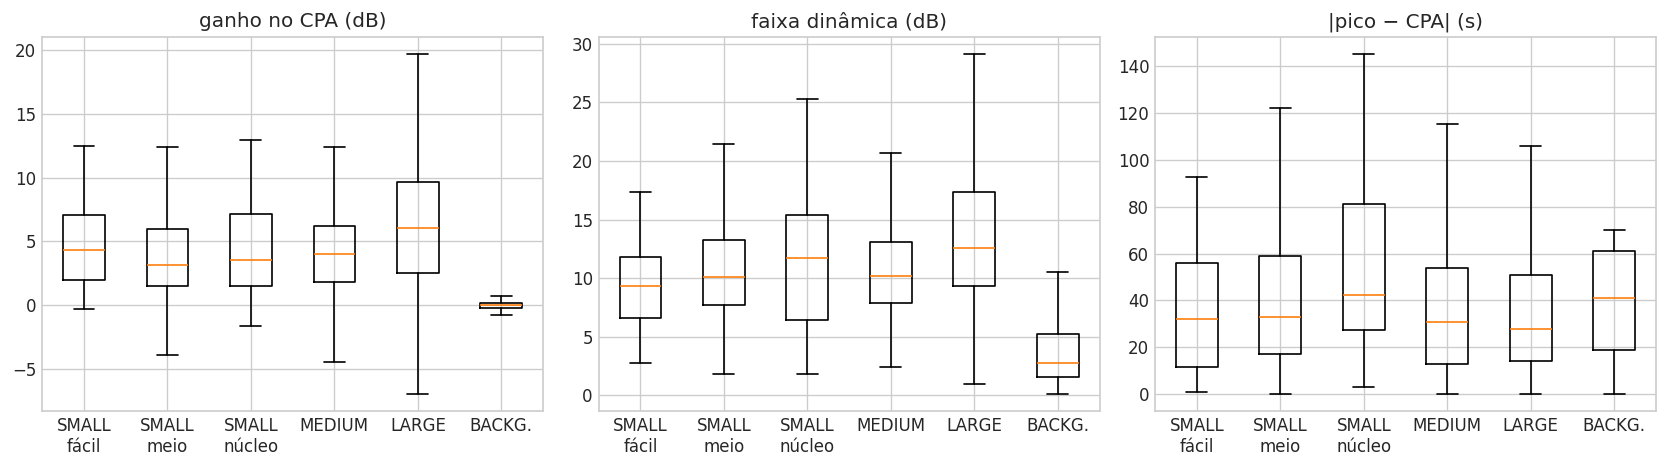

In [6]:
FCOLS = ['ganho no CPA (dB)', 'faixa dinâmica (dB)', '|pico − CPA| (s)', 'nível p50 (dBFS)', 'centroide (Hz)',
         'planura 0–5 kHz', 'energia 0-200 Hz (%)', 'energia 200-1000 Hz (%)', 'energia 1000-5000 Hz (%)',
         'energia 5000-24000 Hz (%)']
if FEAT is None:
    print('Rode scratch/small_acoustic_features.py para gerar', FEAT_CSV)
    AC = AC_CLS = None
else:
    AC = S.groupby('grupo')[FCOLS].median().reindex(ORD)
    AC.loc['p (Kruskal-Wallis)'] = [kruskal(*[S.loc[S.grupo == g, c].dropna() for g in ORD]).pvalue for c in FCOLS]
    AC.loc['ρ Spearman com nº de erros'] = [spearmanr(S[c], S.n_err, nan_policy='omit')[0] for c in FCOLS]
    AC.loc['p (Spearman)'] = [spearmanr(S[c], S.n_err, nan_policy='omit')[1] for c in FCOLS]
    print('SMALL: medianas por grupo'); display(AC.round(3))
    AC_CLS = G.groupby('Classe')[FCOLS].median().reindex(R.CLASSES)
    print('Todas as classes: medianas'); display(AC_CLS.round(2))

    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for a, c in zip(ax, ['ganho no CPA (dB)', 'faixa dinâmica (dB)', '|pico − CPA| (s)']):
        data = [S.loc[S.grupo == g, c].dropna() for g in ORD] + [G.loc[G.Target == k, c].dropna() for k in (1, 2, 3)]
        a.boxplot(data, showfliers=False)
        a.set_xticks(range(1, 7), ['SMALL\nfácil', 'SMALL\nmeio', 'SMALL\nnúcleo', 'MEDIUM', 'LARGE', 'BACKG.'])
        a.set_title(c)
    plt.tight_layout(); plt.show()

**Leitura.**
- Com p < 0,05 entre fácil, meio e núcleo: **centroide (Hz)** (p < 0,001, ρ = -0,38), **planura 0–5 kHz** (p < 0,001, ρ = -0,50), **energia 0-200 Hz (%)** (p < 0,001, ρ = 0,48), **energia 200-1000 Hz (%)** (p = 0,022, ρ = -0,32), **energia 1000-5000 Hz (%)** (p < 0,001, ρ = -0,52), **energia 5000-24000 Hz (%)** (p < 0,001, ρ = -0,29). Ganho mediano no CPA: fácil 4,3 dB, meio 3,2 dB, núcleo 3,5 dB (classes: SMALL 3,3 dB, MEDIUM 4,0 dB, LARGE 6,0 dB, BACKGROUND -0,0 dB). Distância mediana do pico de nível ao CPA anotado: fácil 32 s, meio 33 s, núcleo 42 s.
- **O núcleo tem o espectro concentrado em baixa frequência:** 86% da energia abaixo de 200 Hz (fácil 32%, meio 55%) e centroide de 328 Hz (fácil 1.784 Hz). Na mediana das classes, LARGE tem 72% abaixo de 200 Hz e centroide de 625 Hz; SMALL tem 55% e 1.312 Hz. Acusticamente, o núcleo se parece mais com LARGE do que com o SMALL típico, o que é coerente com 71% das predições irem para LARGE.
- O ganho no CPA (quanto o navio se destaca do fundo) **não** separa os grupos: o barco não está "ausente" das gravações do núcleo. A diferença está em **qual faixa de frequência domina**. A curadoria do IARA (Seção IV-A do artigo) garante um único navio **reportado no AIS** dentro de 2 km, com a região de inclusão de 250 m (A, B) ou 250–500 m (C, D), e verifica que a energia sobe com a aproximação do navio, o que é coerente com o ganho no CPA normal do núcleo. O próprio artigo ressalva que isso **não garante uma gravação pura** do navio: cita barcos sem AIS, falhas no AIS, navios fora da região de exclusão insuficientemente atenuados, navios atracados e outros ruídos antrópicos. Baixa frequência é justamente a faixa que menos se atenua com a distância, então tráfego além de 2 km é uma candidata natural. Outra possibilidade é um regime de operação do próprio barco diferente do habitual. Nenhuma das duas foi testada aqui.
- Essas medidas são aproximações; confirmar que o áudio do núcleo é atípico exige ouvir as gravações e, idealmente, conferir o AIS de outros navios no mesmo horário.

## 6. Para onde vão os erros?

In [7]:
# Para onde vão os erros do SMALL: fração das predições (16 modelos) por classe, por grupo
CF = S.groupby('grupo')[[f'pred {CLS[c]}' for c in range(4)]].mean().reindex(ORD) / NM * 100
CF.columns = R.CLASSES
print('% das predições dos 16 modelos para cada classe (gravações SMALL):'); display(CF.round(1))
CFF = pd.DataFrame({f: {CLS[c]: 100 * np.mean(np.concatenate([d.loc[d.Target == SMALL, list(FAM[f].values())].values.ravel() == c
                                                               for d in AL.values()])) for c in range(4)} for f in FAM}).T
print('Por família (todas as gravações SMALL, 4 entradas):'); display(CFF.round(1))

% das predições dos 16 modelos para cada classe (gravações SMALL):


,SMALL,MEDIUM,LARGE,BACKGROUND
grupo,,,,
fácil,79.8,8.6,5.4,6.1
meio,42.0,21.5,25.9,10.7
núcleo,2.5,11.0,71.3,15.3


Por família (todas as gravações SMALL, 4 entradas):


,SMALL,MEDIUM,LARGE,BACKGROUND
RF,52.9,15.7,28.9,2.4
SVM,36.1,21.1,28.6,14.3
MLP,38.0,20.1,26.0,15.9
BiGRU,43.8,22.4,23.8,10.0


**Leitura.**
- No núcleo, as predições vão para: SMALL 2,5%, MEDIUM 11,0%, LARGE 71,3%, BACKGROUND 15,3%.
- No meio: SMALL 42,0%, MEDIUM 21,5%, LARGE 25,9%, BACKGROUND 10,7%.

## 7. Complementaridade das entradas nas gravações do meio

As 415 gravações SMALL do meio são as que alguns modelos acertam e outros erram. Aqui perguntamos: **qual entrada acerta mais essas gravações, e quais entradas se complementam?**
- **(a)** acerto SMALL de cada modelo nessas gravações;
- **(b)** por gravação, quantas entradas acertam (≥ 50% dos seus 4 modelos × folds) e quantas gravações **só uma** entrada acerta;
- **(c)** Q de Yule dos erros entre entradas, restrito ao meio;
- **(d)** cobertura: % das gravações em que **ao menos uma** das entradas acerta (oráculo);
- **(e)** o custo: quanto cada entrada chama de SMALL o que não é SMALL.

Acerto SMALL (%) nas 415 gravações do meio:


,MEL,LOFAR,HHT,DEMON
RF,57.7,47.0,52.1,53.2
SVM,50.4,36.3,43.4,12.0
MLP,43.6,45.5,26.4,31.9
BiGRU,43.9,56.3,31.3,40.5
média,48.9,46.3,38.3,34.4


Gravações do meio por entrada (nenhuma entrada com ≥ 50%: 76):


,acerta (≥ 50%),só ela acerta,maior acerto da gravação
MEL,220,29,140
LOFAR,196,24,116
HHT,155,17,80
DEMON,138,33,79


Q de Yule dos erros nas gravações do meio:


...

,nº,RF,SVM,MLP,BiGRU,média
entradas,,,,,,
MEL,1,57.9,50.3,43.6,44.0,49.0
LOFAR,1,46.9,36.2,45.3,56.1,46.1
HHT,1,52.9,43.5,26.7,31.3,38.6
DEMON,1,52.5,11.8,32.2,40.3,34.2
MEL + DEMON,2,78.9,55.9,62.9,65.9,65.9
MEL + LOFAR,2,70.5,61.0,61.3,68.3,65.3
MEL + HHT,2,73.5,70.5,57.0,58.8,65.0
LOFAR + DEMON,2,75.3,43.5,63.3,72.7,63.7
LOFAR + HHT,2,66.7,62.5,57.2,68.3,63.7


Falso alarme: % das gravações NÃO SMALL preditas como SMALL


,MEL,LOFAR,HHT,DEMON
RF,22.6,18.3,25.5,35.8
SVM,17.6,11.3,23.4,5.2
MLP,13.7,14.7,12.0,16.4
BiGRU,15.6,23.6,15.1,19.8
média,17.4,17.0,19.0,19.3


Precisão SMALL (%)


,MEL,LOFAR,HHT,DEMON
RF,49.8,50.2,44.7,36.1
SVM,52.7,56.7,41.8,46.9
MLP,55.7,54.9,48.3,43.1
BiGRU,52.8,47.7,46.3,44.1
média,52.7,52.4,45.3,42.6


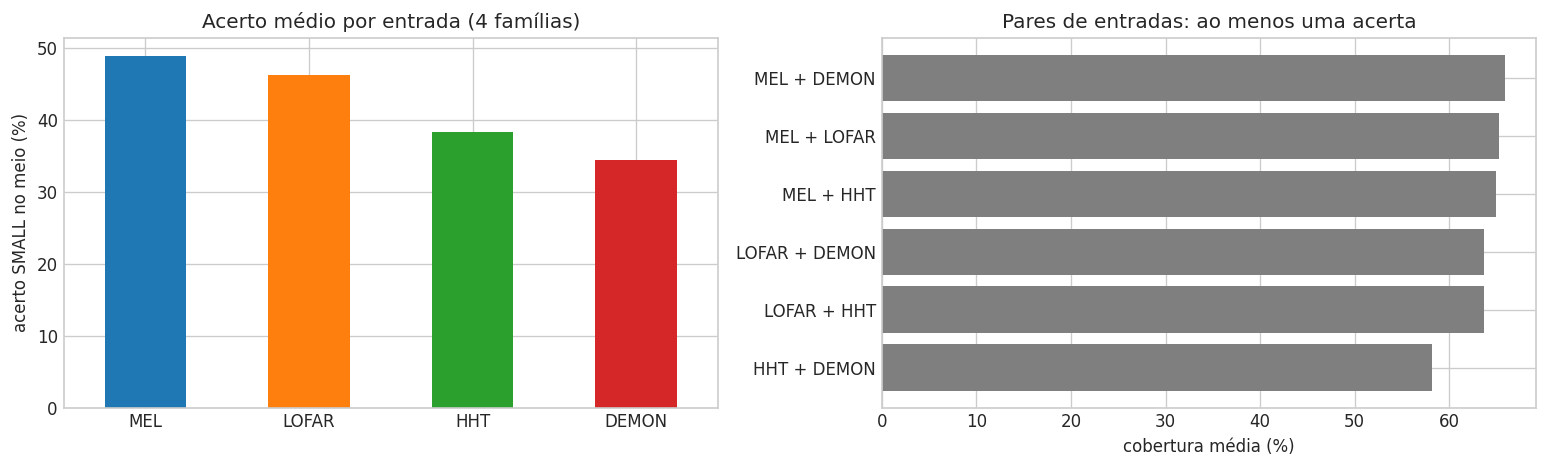

In [8]:
import itertools
REP = ['MEL', 'LOFAR', 'HHT', 'DEMON']
M = S[S.grupo == 'meio']
Im = I[I.File.isin(M.index)]

# (a) Acerto SMALL por família × entrada nas gravações do meio
ACM = pd.DataFrame({f: {r: 100 * (1 - M[f'{f} {r}'].mean()) for r in REP} for f in FAM}).T
ACM.loc['média'] = ACM.mean()
print(f'Acerto SMALL (%) nas {len(M)} gravações do meio:'); display(ACM.round(1))

# (b) Por gravação: acerto de cada entrada = média dos 4 modelos (famílias) × folds
A = pd.DataFrame({r: 1 - M[[f'{f} {r}' for f in FAM]].mean(axis=1) for r in REP})
EXC = pd.DataFrame({'acerta (≥ 50%)': (A >= 0.5).sum(),
                    'só ela acerta': [int(((A[r] >= 0.5) & (A.drop(columns=r) < 0.5).all(axis=1)).sum()) for r in REP],
                    'maior acerto da gravação': A.idxmax(axis=1).value_counts().reindex(REP).fillna(0).astype(int)})
N_NENHUMA = int((A < 0.5).all(axis=1).sum())
print(f'Gravações do meio por entrada (nenhuma entrada com ≥ 50%: {N_NENHUMA}):'); display(EXC)

# (c) Q de Yule dos erros entre entradas, só nas gravações do meio (por família e fold)
def q_yule(a, b):
    n11, n00, n10, n01 = (a & b).sum(), (~a & ~b).sum(), (a & ~b).sum(), (~a & b).sum()
    return (n11 * n00 - n10 * n01) / (n11 * n00 + n10 * n01)
QM = pd.DataFrame({f'{a} × {b}': {f: np.nanmean([q_yule(g[f'{f} {a}'].values == 1, g[f'{f} {b}'].values == 1)
                                                for _, g in Im.groupby('fold')]) for f in FAM}
                   for a, b in itertools.combinations(REP, 2)})
QM.loc['média'] = QM.mean()
print('Q de Yule dos erros nas gravações do meio:'); display(QM.round(2))

# (d) Cobertura: % das gravações do meio (por fold) em que ao menos uma das entradas acerta
rows = []
for k in range(1, 5):
    for comb in itertools.combinations(REP, k):
        r = {'entradas': ' + '.join(comb), 'nº': k}
        for f in FAM:
            r[f] = 100 * (Im[[f'{f} {x}' for x in comb]] == 0).any(axis=1).mean()
        rows.append(r)
COB = pd.DataFrame(rows).set_index('entradas')
COB['média'] = COB[list(FAM)].mean(axis=1)
COB = COB.sort_values(['nº', 'média'], ascending=[True, False])
print('Cobertura (oráculo) nas gravações do meio (%):'); display(COB.round(1))

# (e) Custo: quanto cada entrada chama de SMALL o que não é SMALL (todas as gravações de teste)
fa, pr = {}, {}
for f, reps in FAM.items():
    fa[f], pr[f] = {}, {}
    for r, e in reps.items():
        y = np.concatenate([d.Target.values for d in AL.values()]); p = np.concatenate([d[e].values for d in AL.values()])
        fa[f][r] = 100 * np.mean(p[y != SMALL] == SMALL)
        pr[f][r] = 100 * np.mean(y[p == SMALL] == SMALL)
FA, PR = pd.DataFrame(fa).T[REP], pd.DataFrame(pr).T[REP]
FA.loc['média'], PR.loc['média'] = FA.mean(), PR.mean()
print('Falso alarme: % das gravações NÃO SMALL preditas como SMALL'); display(FA.round(1))
print('Precisão SMALL (%)'); display(PR.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ACM.loc['média'].plot.bar(ax=ax[0], color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], rot=0)
ax[0].set_ylabel('acerto SMALL no meio (%)'); ax[0].set_title('Acerto médio por entrada (4 famílias)')
top = COB[COB['nº'] == 2]['média'].sort_values()
ax[1].barh(top.index, top.values, color='tab:gray'); ax[1].set_xlabel('cobertura média (%)')
ax[1].set_title('Pares de entradas: ao menos uma acerta'); plt.tight_layout(); plt.show()

**Leitura.**
- **Quem mais acerta:** em média, MEL 48,9%, LOFAR 46,3%, HHT 38,3%, DEMON 34,4%. A melhor entrada muda com a família: RF → MEL, SVM → MEL, MLP → LOFAR, BiGRU → LOFAR.
- **Quem acerta sozinha:** MEL 29, LOFAR 24, HHT 17, DEMON 33 gravações; em 76 nenhuma entrada passa de 50%. **DEMON** é a que mais acerta gravações que as outras erram.
- **Erram juntas?** Q de Yule no meio: MEL × LOFAR 0,57, MEL × HHT 0,32, MEL × DEMON -0,04, LOFAR × HHT 0,31, LOFAR × DEMON 0,02, HHT × DEMON -0,02. MEL × LOFAR continua o par mais redundante; os pares com DEMON ficam em torno de zero (-0,04 a 0,02): nessas gravações, o DEMON erra de forma praticamente independente das outras entradas. Restringir ao meio (tirar as gravações que todos acertam ou todos erram) reduz o Q de todos os pares; o que vale é a comparação entre pares, não o valor absoluto.
- **Cobertura (oráculo):** melhor par MEL + DEMON (65,9%), e MEL + LOFAR 65,3%; melhor trio MEL + LOFAR + DEMON (76,4%) contra 74,8% do trio sem DEMON; as quatro, 82,7%. Melhor par por família: RF MEL + DEMON, SVM MEL + HHT, MLP LOFAR + DEMON, BiGRU LOFAR + DEMON.
- **O custo:** o DEMON chama de SMALL 19,3% das gravações que não são SMALL em média, perto das outras entradas (17,0–19,0%), mas 35,8% no RF, onde ele mais acerta SMALL. Tem a menor precisão SMALL (42,6%, contra 52,7% do MEL). Uma regra simples como "aceitar SMALL se o DEMON disser SMALL" ganharia recall SMALL e perderia em MEDIUM e LARGE.

**Como combinar MEL e DEMON?** A cobertura é um teto: supõe saber, em cada gravação, qual entrada seguir. Caminhos, do mais simples ao mais elaborado:
1. **Média ponderada das probabilidades** (fusão tardia): p = w·p_MEL + (1 − w)·p_DEMON, com w escolhido na validação. Simples, mas trata o DEMON igual em todas as classes.
2. **Stacking:** um classificador pequeno (regressão logística) recebe as 8 probabilidades (4 classes × 2 entradas) e aprende quando confiar em cada uma, por exemplo que um "SMALL" do DEMON vale mais quando o MEL hesita entre SMALL e LARGE e menos quando o MEL está confiante em MEDIUM.
3. **Fusão de características** (concatenar MEL e DEMON na entrada de um único modelo), já testada no Notebook 30 com o MLP.
4. **Gating por confiança:** usar o DEMON só quando a confiança do MEL (margem entre as duas maiores probabilidades) for baixa.

As fusões com DEMON testadas nos Notebooks 30 e 31 não deram ganho significativo no SP; o stacking (2) é o candidato que modela explicitamente o falso alarme do DEMON.

## 8. O MEL estava inseguro quando errou?

Se os erros do MEL em SMALL fossem indecisão, daria para usar a confiança dele: chamar o DEMON só quando o MEL estiver inseguro (gating), ou favorecer o SMALL quando ele for a 2ª opção. Medimos a confiança de cinco modelos MEL (RF, SVM, MLP, BiGRU, CNN) em cada gravação SMALL:
- **concordância das janelas:** fração das janelas que votam na classe vencedora (existe para todos);
- **margem:** diferença entre as duas maiores probabilidades médias da gravação (o SVM não guarda probabilidades);
- **AUC:** quanto a medida separa acertos de erros (0,5 = não separa; 1 = separa perfeitamente).

Depois testamos as duas ideias: (b) gating com concordância < 0,6 e (c) somar δ à probabilidade do SMALL.

MEL nas gravações SMALL: confiança quando acerta × quando erra (medianas; AUC = 0,5 é não separar)


,erro SMALL (%),concordância: acerto,concordância: erro,AUC concordância,margem: acerto,margem: erro,AUC margem,SMALL 2ª opção nos erros SMALL (%),SMALL 2ª opção nos acertos de outras classes (%)
família,,,,,,,,,
RF,42.13,0.79,0.69,0.59,0.14,0.11,0.54,78.27,74.81
SVM,49.27,0.73,0.68,0.55,NaN,NaN,NaN,NaN,NaN
MLP,55.23,0.63,0.63,0.49,0.18,0.17,0.50,66.94,62.09
BiGRU,54.72,0.82,0.78,0.53,0.31,0.28,0.53,63.14,53.41
CNN,52.58,0.85,0.85,0.53,0.28,0.22,0.54,71.05,65.35


Concordância mediana das janelas nos ERROS, por classe verdadeira:


Target,SMALL,MEDIUM,LARGE,BACKGROUND
fam,,,,
BiGRU,0.78,0.78,0.78,1.00
CNN,0.85,0.85,0.77,1.00
MLP,0.63,0.63,0.60,0.69
RF,0.69,0.71,0.64,0.90
SVM,0.68,0.67,0.63,0.78


Gating pela confiança do MEL (concordância < 0.6):


,erros marcados como inseguros (%),acertos marcados como inseguros (%),DEMON acerta nos erros inseguros (%),DEMON acerta nos erros seguros (%)
família,,,,
RF,34.8,20.3,39.5,47.2
SVM,35.3,28.9,9.4,10.9
MLP,44.4,44.0,33.9,29.3
BiGRU,25.4,21.8,36.8,36.2
CNN,17.5,14.1,34.1,29.0


Somar δ à probabilidade do SMALL (escolhido no próprio teste, portanto otimista):


SP  recall SMALL  recall MEDIUM  recall LARGE  recall BACKGROUND
família δ                                                                       
RF      0.00  62.0          57.4           59.7          68.2               63.1
        0.05  60.9          68.2           52.3          63.4               60.4
        0.10  59.2          76.5           45.3          59.7               57.9
        0.20  53.1          86.0           29.5          52.4               52.7
MLP     0.00  64.7          45.4           63.6          68.0               85.7
        0.05  65.1          52.7           59.1          66.5               85.0
        0.10  64.7          58.6           54.4          64.3               83.9
        0.20  64.1          70.4           46.8          59.6               83.0
BiGRU   0.00  63.4          44.7           62.3          69.0               80.8
        0.05  63.1          48.4           59.4          67.5               79.8
        0.10  63.6          53.4           57.6          66.3               78.9
        0.20  63.4          61.7           53.2          62.6               77.8
CNN     0.00  65.8          48.1           62.6          67.5               88.2
        0.05  65.4          53.1           58.3          65.3               87.2
        0.10  65.3          58.6           54.7          63.6               86.8
        0.20  64.7          68.9           48.5          58.8               85.6

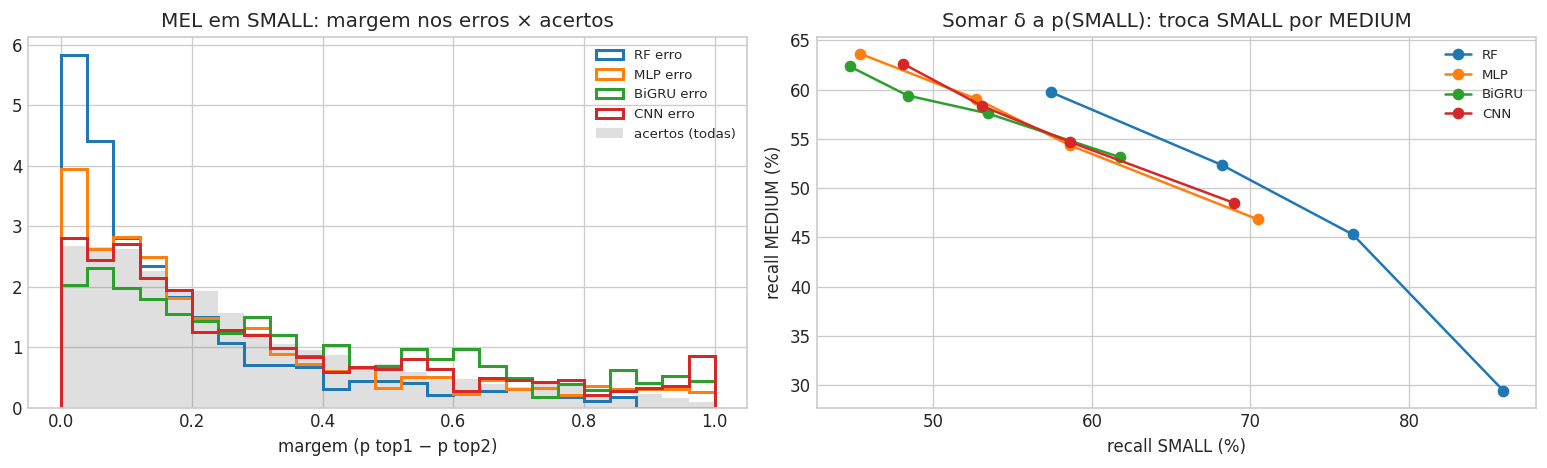

In [9]:
from sklearn.metrics import roc_auc_score
from scipy.stats import gmean

PARES_MD = {  # família: (MEL, DEMON)
    'RF': (FAM['RF']['MEL'], FAM['RF']['DEMON']), 'SVM': (FAM['SVM']['MEL'], FAM['SVM']['DEMON']),
    'MLP': (FAM['MLP']['MEL'], FAM['MLP']['DEMON']), 'BiGRU': (FAM['BiGRU']['MEL'], FAM['BiGRU']['DEMON']),
    'CNN': ('cnn_mel_artigo', 'hcnn_demon_tpsw_med5_e60p8_4c'),
}

def prob_medias(name):
    # {fold: DataFrame(File, p0..p3)}: média por gravação das saídas por janela (normalizadas para somar 1);
    # None se o experimento não guardou probabilidades (SVM)
    d = R.exp_dir(name); out = {}
    for k in range(10):
        df = pd.read_csv(os.path.join(d, 'eval', f'fold_{k}', f'{name}_multiclass_test.csv'))
        cols = [f'Prediction_{c}' for c in range(4)]
        if not set(cols) <= set(df.columns):
            return None
        P = df[cols].clip(lower=0).values
        P = P / np.maximum(P.sum(1, keepdims=True), 1e-12)
        g = pd.DataFrame(P, columns=['p0', 'p1', 'p2', 'p3']); g['File'] = df.File.values
        out[k] = g.groupby('File').mean().reset_index()
    return out

rows = []
for fam, (mel, dem) in PARES_MD.items():
    fp, fd, sc = R.file_predictions(mel), R.file_predictions(dem), prob_medias(mel)
    for k in range(10):
        a = fp[k].merge(fd[k][['File', 'Prediction']].rename(columns={'Prediction': 'pred_demon'}), on='File')
        if sc is not None:
            a = a.merge(sc[k], on='File')
        a['fam'], a['fold'] = fam, k
        rows.append(a)
D = pd.concat(rows, ignore_index=True)
D['acertou'] = D.Prediction == D.Target
Pm = D[['p0', 'p1', 'p2', 'p3']].values
D['margem'] = np.sort(Pm, 1)[:, -1] - np.sort(Pm, 1)[:, -2]
D['rank SMALL'] = (Pm > Pm[:, [0]]).sum(1) + 1
D['gap SMALL'] = D[['p0', 'p1', 'p2', 'p3']].max(axis=1) - D.p0
DS = D[D.Target == SMALL]

# (a) confiança nos acertos × erros do SMALL
cf = []
for fam, g in DS.groupby('fam', sort=False):
    ok, er = g[g.acertou], g[~g.acertou]
    r = {'família': fam, 'erro SMALL (%)': 100 * len(er) / len(g),
         'concordância: acerto': ok.agreement.median(), 'concordância: erro': er.agreement.median(),
         'AUC concordância': roc_auc_score(g.acertou, g.agreement)}
    if g.margem.notna().all():
        on = D[(D.fam == fam) & (D.Target != SMALL) & D.acertou]
        r.update({'margem: acerto': ok.margem.median(), 'margem: erro': er.margem.median(),
                  'AUC margem': roc_auc_score(g.acertou, g.margem),
                  'SMALL 2ª opção nos erros SMALL (%)': 100 * (er['rank SMALL'] == 2).mean(),
                  'SMALL 2ª opção nos acertos de outras classes (%)': 100 * (on['rank SMALL'] == 2).mean()})
    cf.append(r)
CONF = pd.DataFrame(cf).set_index('família')
print('MEL nas gravações SMALL: confiança quando acerta × quando erra (medianas; AUC = 0,5 é não separar)')
display(CONF.round(3))
ERR_OUT = D[~D.acertou].groupby(['fam', D.Target.map(CLS)]).agreement.median().unstack()[R.CLASSES]
print('Concordância mediana das janelas nos ERROS, por classe verdadeira:'); display(ERR_OUT.round(3))

# (b) gating: limiar de concordância 0,6 -> o que ele separa e se o DEMON acerta nos erros inseguros
THR = 0.6
gt = []
for fam, g in DS.groupby('fam', sort=False):
    er, ok = g[~g.acertou], g[g.acertou]
    ins = er.agreement < THR
    gt.append({'família': fam, 'erros marcados como inseguros (%)': 100 * ins.mean(),
               'acertos marcados como inseguros (%)': 100 * (ok.agreement < THR).mean(),
               'DEMON acerta nos erros inseguros (%)': 100 * (er[ins].pred_demon == SMALL).mean(),
               'DEMON acerta nos erros seguros (%)': 100 * (er[~ins].pred_demon == SMALL).mean()})
GATE = pd.DataFrame(gt).set_index('família')
print(f'Gating pela confiança do MEL (concordância < {THR}):'); display(GATE.round(1))

# (c) deslocar o limiar do SMALL: somar δ a p(SMALL) (predição pela média das probabilidades)
sh = []
for fam, g in D[D.margem.notna()].groupby('fam', sort=False):
    for delta in (0, 0.05, 0.10, 0.20):
        rec, sps = [], []
        for _, h in g.groupby('fold'):
            P = h[['p0', 'p1', 'p2', 'p3']].values.copy(); P[:, 0] += delta
            pr, y = P.argmax(1), h.Target.values
            rc = np.array([np.mean(pr[y == c] == c) for c in range(4)])
            rec.append(rc); sps.append(np.sqrt(rc.mean() * gmean(rc)) * 100 if (rc > 0).all() else 0)
        sh.append({'família': fam, 'δ': delta, 'SP': np.mean(sps),
                   **{f'recall {CLS[c]}': v for c, v in enumerate(np.mean(rec, 0) * 100)}})
SHIFT = pd.DataFrame(sh).set_index(['família', 'δ'])
print('Somar δ à probabilidade do SMALL (escolhido no próprio teste, portanto otimista):'); display(SHIFT.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for fam, g in DS[DS.margem.notna()].groupby('fam', sort=False):
    ax[0].hist(g[~g.acertou].margem, bins=np.linspace(0, 1, 26), histtype='step', lw=1.8, density=True, label=f'{fam} erro')
ax[0].hist(DS[DS.acertou & DS.margem.notna()].margem, bins=np.linspace(0, 1, 26), histtype='stepfilled', alpha=0.25,
           color='gray', density=True, label='acertos (todas)')
ax[0].set_xlabel('margem (p top1 − p top2)'); ax[0].set_title('MEL em SMALL: margem nos erros × acertos'); ax[0].legend(fontsize=8)
for fam in SHIFT.index.get_level_values(0).unique():
    t = SHIFT.loc[fam]
    ax[1].plot(t['recall SMALL'], t['recall MEDIUM'], marker='o', label=fam)
ax[1].set_xlabel('recall SMALL (%)'); ax[1].set_ylabel('recall MEDIUM (%)')
ax[1].set_title('Somar δ a p(SMALL): troca SMALL por MEDIUM'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **Não estava inseguro.** A AUC da concordância vai de 0,49 a 0,59 e a da margem de 0,50 a 0,54: a confiança do MEL praticamente não distingue os erros dos acertos em SMALL. A concordância mediana nos erros em SMALL é parecida com a dos erros em MEDIUM e LARGE.
- **Gating pela confiança não isola os erros:** com concordância < 0,6, RF marca 35% dos erros e 20% dos acertos; SVM marca 35% dos erros e 29% dos acertos; MLP marca 44% dos erros e 44% dos acertos; BiGRU marca 25% dos erros e 22% dos acertos; CNN marca 18% dos erros e 14% dos acertos. E o DEMON acerta mais nos erros inseguros do que nos seguros em só 3 das 5 famílias.
- **SMALL como 2ª opção não é específico:** o SMALL é a 2ª opção em 63–78% dos erros em SMALL, mas também em 53–75% das gravações de outras classes que o MEL acerta.
- **Favorecer o SMALL troca SMALL por MEDIUM:** com δ = 0,2, o recall SMALL sobe 17,0–28,5 pontos e o MEDIUM cai 9,2–30,3; o SP varia de -8,9 a 0,0 pontos. Mesmo escolhendo δ no próprio teste (otimista), não há ganho.
- **Leitura física:** o MEL erra o SMALL com a mesma convicção com que acerta as outras classes; para ele, essas gravações **parecem** MEDIUM ou LARGE (coerente com a Seção 5). Combinações que dependem de o MEL "hesitar" (gating, limiar) não têm onde atuar; resta o stacking, que aprende combinações das probabilidades das duas entradas sem depender da confiança do MEL.

## 9. Conclusões

1. **O núcleo é pequeno:** 26 das 476 gravações SMALL (5,5%), de 15 navios, são erradas por quase todos os modelos. Ele não explica, sozinho, um recall SMALL de ~45%.
2. **O problema principal está no meio:** 87% das gravações SMALL são acertadas por alguns modelos e erradas por outros. Não dá para afirmar que o recall SMALL não pode melhorar "independentemente da entrada".
3. **Generalização para navios novos pesa:** ter o navio no treino reduz o erro e o split por navio derruba o recall SMALL; aumentar o número de navios SMALL (e não de gravações do mesmo navio) é provavelmente mais útil que trocar a entrada.
4. **O núcleo é acusticamente atípico, não necessariamente defeituoso:** as gravações têm energia concentrada abaixo de 200 Hz, como as de navios grandes, e os modelos as chamam de LARGE. Os metadados (CPA, clima, subconjunto) não explicam isso. A lista (`reports/small/nucleo_small.csv`) é o ponto de partida para escuta e conferência manual (AIS de outros navios no horário).
5. **No meio, o DEMON é a entrada complementar:** acerta sozinho mais gravações que as outras entradas (33) e erra de forma quase independente delas (Q médio ≈ -0,01), mas tem a menor precisão SMALL (42,6%) e, no RF, um falso alarme de SMALL de 35,8%. MEL + DEMON é o par de maior cobertura; o ganho só aparece com um combinador que aprenda quando confiar no DEMON.
6. **Os erros do MEL em SMALL não são indecisão:** a confiança dele não separa erros de acertos (AUC 0,49–0,59); gating pela confiança e favorecer o SMALL não melhoram o SP.
7. **O efeito vai além do núcleo:** a correlação entre energia abaixo de 200 Hz e o número de modelos que erram vale para todo o SMALL (ρ de Spearman = 0,48): quanto mais grave o espectro de uma gravação SMALL, mais modelos a erram.

**Limites:**
- 16 modelos de 4 famílias; a CNN só entra na Seção 8 (CNN MEL), porque não tem as 4 entradas avaliadas no mesmo protocolo.
- "Erram" é a média de 5 folds; as gravações se repetem entre as repetições do 5×2cv.
- As medidas acústicas não são calibradas e misturam subconjuntos com equipamentos diferentes.
- Navios com uma só gravação não permitem separar efeito do navio e da gravação.